# Rio Bradano (HARMONIOUS): velocidad superficial con STIV sobre un video ortorrectificado

Notebook autocontenido que implementa **STIV** (*Space-Time Image Velocimetry*) sobre **OpenCV**,
paso a paso, y lo aplica al rio Bradano (Basilicata, Italia) a partir de un video de dron que el
propio dataset entrega **ya ortorrectificado y estabilizado**. No se usa ninguna libreria de
velocimetria: OpenCV aporta la lectura del video, el muestreo bilineal y las derivadas; el resto
esta escrito aqui. pyorc no se importa en ningun momento.

Pasos:

1. Abrir el video y extraer un fotograma
2. Fijar la escala y la geometria de la seccion: de pixeles a metros
3. Construir las imagenes espacio-temporales (STI) sobre las lineas de busqueda
4. Medir la pendiente de las estelas con el tensor de estructura, y filtrar las malas
5. Componer el perfil transversal de velocidad superficial

Los datos son del dataset **HARMONIOUS** de intercomparacion de tecnicas de velocimetria por
imagen en rios, carpeta `RiverBradano`.

**No hay ningun detector automatico.** Todo lo que depende del caso es una constante marcada
`>>> AJUSTABLE <<<`, y cada una esta **al principio del bloque donde se usa**, con la explicacion
de que es y para que sirve. Las que salen del propio dataset llevan la marca *(obtenido del
dataset)*. El resumen de cuales son y donde estan esta al final del notebook.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera (figuras
PNG, CSV de resultados y el JSON de configuracion) se escribe en `salidas/`.**

## Que hace distinto a este caso

Los tres casos de STIV que ya hay en el workspace se apoyaban, cada uno a su manera, en resolver
la geometria: el Sile Main Canal deducia la escala de dos lineas de agua leidas a mano, Boneyard
Creek tenia que inventarse un horizonte porque el dataset no daba ninguna longitud, y Hommerich
resolvia la pose completa de la camara con `solvePnP`. **Aqui no hay nada de eso que hacer.** El
dataset entrega el video ya ortorrectificado y estabilizado, y declara su escala: 0.009 m/px. La
vista es cenital y plana, asi que el fotograma **es** el plano del agua.

Eso deja el caso reducido a lo que el metodo tiene de propio, que es justo lo interesante, y
saca a la luz una dificultad distinta: **el trazador es disperso**. El agua del Bradano sale
practicamente negra (brillo medio 0.12 sobre 255 en la zona mojada) y lo unico que se ve son
particulas brillantes sueltas. No es una textura continua como la espuma del Sile o del Arrow: son
puntos aislados sobre un fondo sin nada. Una linea de busqueda de un pixel de ancho pasa la mayor
parte del tiempo sin ver ninguna, y el tensor no tiene de donde sacar una orientacion.

La respuesta esta en la Parte 3: la linea se sustituye por una **banda** de lineas paralelas cuyas
STI se promedian. Es la unica desviacion de este notebook respecto a los otros tres, esta medida, y
la tabla que la justifica esta en su sitio.

## Que es STIV y en que se diferencia del PIV

El PIV correla **parches 2D** entre dos fotogramas consecutivos y devuelve un vector por parche.
STIV renuncia a la segunda dimension: fija de antemano **la direccion del flujo**, muestrea una
sola linea orientada en esa direccion, y apila esa linea a lo largo del tiempo. En la imagen que
resulta -- espacio en horizontal, tiempo en vertical -- cada trozo de agua que viaja por la linea
deja una **estela recta**, y su pendiente *es* la velocidad. Medir la velocidad se convierte en
medir la orientacion dominante de una textura, que es un problema resuelto: el **tensor de
estructura**.

El precio es que hay que darle la direccion del flujo, y a cambio se gana robustez (una estela se
integra sobre cientos de fotogramas, no sobre dos) y un consumo de memoria que no depende de la
longitud del video.

---
## Parte 0 - Rutas de trabajo

Los datos viven **fuera del workspace**, en el disco donde esta descargado el dataset HARMONIOUS,
asi que las rutas de entrada son absolutas a proposito. Todo lo que se genera se escribe en
`salidas/`, al lado de este notebook, y el notebook se ejecuta **desde su propia carpeta**.

El video que se procesa es el de la carpeta `Stabilised`. El dataset trae tambien la version
`Non-stabilised`, y la eleccion no es indiferente: el `Readme.txt` dice que las coordenadas en
pixeles de los datos de validacion estan referidas **al primer fotograma de la imagen
estabilizada**. Usar esa version es lo que permite comparar punto a punto en la Parte 7 sin
registrar nada.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
# Rutas absolutas: el dataset HARMONIOUS esta fuera del workspace.
DIR_DATOS = Path(r"C:\Users\Sergio\Desktop\datasets vision velocimetria\data\RiverBradano")
ARCHIVO_VIDEO = DIR_DATOS / "Stabilised" / "Video" / "RiverBradano_24_fps_Stabilised.avi"
# Del fichero de validacion se leen aqui SOLO las coordenadas de las verticales. Las
# velocidades de referencia no se abren hasta la Parte 7.
ARCHIVO_VALIDACION = DIR_DATOS / "Reference" / "Validation_Data_RiverBradano.xlsx"

# --- Salidas ---
DIR_SALIDA = Path("salidas")
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config_stiv.json"          # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"    # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"              # comparacion final
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Dataset en:", DIR_DATOS)
for entrada in (ARCHIVO_VIDEO, ARCHIVO_VALIDACION):
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Dataset en: C:\Users\Sergio\Desktop\datasets vision velocimetria\data\RiverBradano
  OK    RiverBradano_24_fps_Stabilised.avi
  OK    Validation_Data_RiverBradano.xlsx


---
## Parte 1 - Lectura del video

`cv2.VideoCapture` da acceso al video y a sus metadatos. De aqui salen dos cosas que hacen falta
luego: la **cadencia** (para convertir fotogramas en segundos) y un fotograma sobre el que
comprobar visualmente toda la geometria.

$$ \Delta t = \frac{1}{\mathrm{fps}} $$

El video es de 1920x1080 a 24 fps y dura 25 s exactos (600 fotogramas), y esta grabado en escala
de grises. Viene comprimido con perdida, que es lo unico incomodo de este caso: STIV estima la
pendiente a partir de gradientes de intensidad, y un codec con perdida mete ruido de bloque justo
ahi. No hay alternativa -- el dataset no publica los fotogramas sin comprimir -- y se anota como
limitacion al final.

Resolucion : 1920 x 1080 px
Cadencia   : 24.0000 fps  ->  DT = 41.667 ms entre fotogramas
Fotogramas : 600 (25.0 s)


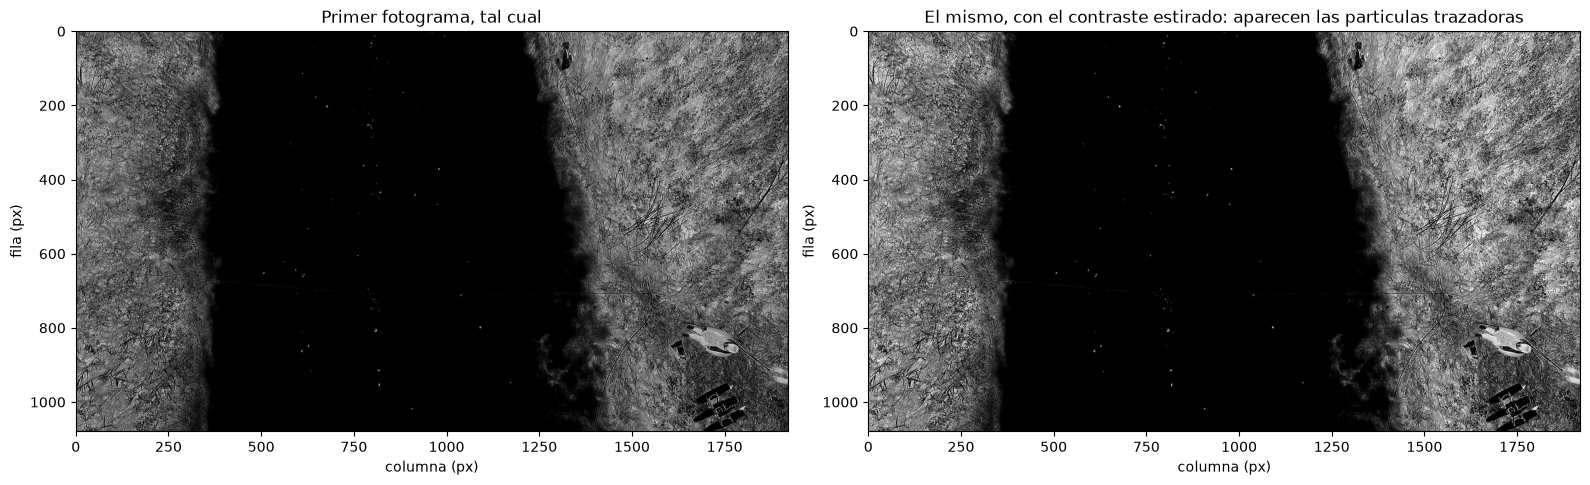

In [2]:
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
if not cap.isOpened():
    raise SystemExit(f"No se pudo abrir {ARCHIVO_VIDEO}")

FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ANCHO_PX = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO_PX = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
ok, frame_bgr = cap.read()
cap.release()

# DT es el intervalo entre fotogramas: aparece en la formula final de la velocidad.
DT = 1.0 / FPS
frame_gris = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)

print(f"Resolucion : {ANCHO_PX} x {ALTO_PX} px")
print(f"Cadencia   : {FPS:.4f} fps  ->  DT = {DT*1000:.3f} ms entre fotogramas")
print(f"Fotogramas : {N_TOTAL} ({N_TOTAL/FPS:.1f} s)")

# El agua sale casi negra, asi que junto al fotograma tal cual se muestra una version con el
# contraste estirado. Sin ella, en la figura no se ve absolutamente nada dentro del cauce, y lo
# que hay que comprobar (que si hay particulas trazadoras) es justamente lo que se pierde.
lo, hi = np.percentile(frame_gris, [1, 99.5])
frame_realce = np.clip((frame_gris.astype(np.float32) - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(frame_gris, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Primer fotograma, tal cual")
axes[1].imshow(frame_realce, cmap="gray")
axes[1].set_title("El mismo, con el contraste estirado: aparecen las particulas trazadoras")
for ax in axes:
    ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig1_primer_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Escala y geometria de la seccion

### La escala la da el dataset

Aqui no hay que deducirla. El `Readme.txt` del Bradano declara que la imagen estabilizada tiene
una resolucion de **0.009 m/px**, porque el video ya viene ortorrectificado: es una proyeccion
sobre el plano del agua, no una vista en perspectiva. Eso elimina de golpe la mayor fuente de
incertidumbre de los otros casos del workspace.

Conviene aun asi **comprobarla**, y el propio dataset da con que. Las siete verticales de
validacion estan en las columnas 456, 567, 678, 789, 900, 1011 y 1122: separadas **exactamente
111 px**. A 0.009 m/px eso son **0.999 m**. Un aforo se hace en verticales espaciadas un numero
redondo de metros, asi que esa coincidencia es una confirmacion independiente de la escala, y no
usa ninguna velocidad de referencia: solo las posiciones.

### Las lineas de busqueda

La seccion de aforo es la **fila 706** de la imagen, y el flujo va en vertical, asi que cada linea
de busqueda es una columna. Las estaciones se colocan en la misma malla de 1 m que usa el dataset,
extendida hasta cubrir el ancho mojado: siete de ellas caen sobre verticales de validacion y las
dos ultimas se anaden para que el perfil llegue hasta la orilla derecha.

Las dos lineas de agua se leen a ojo sobre el perfil de brillo. En este video es facil, y por una
vez a favor: el agua es **negra** (brillo medio por debajo de 0.5 niveles de gris) y las orillas
son grava clara (60-115). El escalon es de dos ordenes de magnitud.

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria: lo unico que liga pixeles con metros
# ---------------------------------------------------------------------------------------
# Escala de la imagen ortorrectificada, declarada por el Readme.txt del dataset para la
# version estabilizada. No se deduce de nada: se toma. (obtenido del dataset)
ESCALA = 0.009                # m/px

# Fila de la imagen donde esta la seccion de aforo, la misma sobre la que el dataset da las
# velocidades de referencia. (obtenido del dataset)
FILA_SECCION = 706

# Columnas donde el agua toca cada orilla, en la fila de la seccion. Se leen sobre el perfil
# de brillo de la figura de abajo, que cae de ~60 a <1 nivel de gris en unos pocos pixeles.
# Solo sirven para situar el perfil y para rechazar las estaciones cuya banda pisa la orilla:
# la escala NO sale de aqui, al contrario que en el caso del Sile Main Canal.
COLUMNA_AGUA_IZQ = 383
COLUMNA_AGUA_DER = 1353

# Malla de estaciones: la del propio aforo (1 m, o sea 111 px, empezando en la columna 456),
# prolongada aguas a la derecha hasta donde quepa dentro del agua. Las siete primeras
# coinciden con las verticales de validacion. (obtenido del dataset)
COLUMNA_ESTACION_0 = 456
PASO_ESTACION_PX = 111
N_ESTACIONES = 9

# Direccion del flujo en la imagen, en grados desde el eje +x (columnas), positiva hacia
# abajo. El Bradano corre aqui de abajo arriba en el fotograma, o sea -90 grados. No es una
# suposicion: la correlacion de fase entre fotogramas consecutivos, medida sobre parches de
# agua repartidos por el cauce, da desviaciones respecto a la vertical de -0.6, +0.1, -3.9 y
# -10.0 grados de izquierda a derecha, y la ultima es donde el agua esta casi parada y el
# angulo ya no significa nada. Un error de 4 grados cuesta un 0.2 % en el modulo (cos 4).
ANGULO_FLUJO = -90.0          # grados
# ---------------------------------------------------------------------------------------

# Las estaciones y su progresiva desde la orilla izquierda.
columnas_estaciones = COLUMNA_ESTACION_0 + PASO_ESTACION_PX * np.arange(N_ESTACIONES)
s_estaciones = (columnas_estaciones - COLUMNA_AGUA_IZQ) * ESCALA

ANCHO_MOJADO_PX = COLUMNA_AGUA_DER - COLUMNA_AGUA_IZQ
print(f"Escala declarada por el dataset: {ESCALA*1000:.2f} mm/px")
print(f"Ancho mojado en la fila {FILA_SECCION}: {ANCHO_MOJADO_PX} px = {ANCHO_MOJADO_PX*ESCALA:.2f} m")
print(f"Separacion entre verticales de validacion: {PASO_ESTACION_PX} px = "
      f"{PASO_ESTACION_PX*ESCALA:.4f} m  <- comprobacion de la escala")
print(f"\n{N_ESTACIONES} estaciones en las columnas {columnas_estaciones.tolist()}")

Escala declarada por el dataset: 9.00 mm/px
Ancho mojado en la fila 706: 970 px = 8.73 m
Separacion entre verticales de validacion: 111 px = 0.9990 m  <- comprobacion de la escala

9 estaciones en las columnas [456, 567, 678, 789, 900, 1011, 1122, 1233, 1344]


Verticales de validacion del dataset (solo posiciones):
  columnas [456, 567, 678, 789, 900, 1011, 1122]
  filas    [706, 706, 706, 706, 706, 706, 706]   (todas en la fila de la seccion)


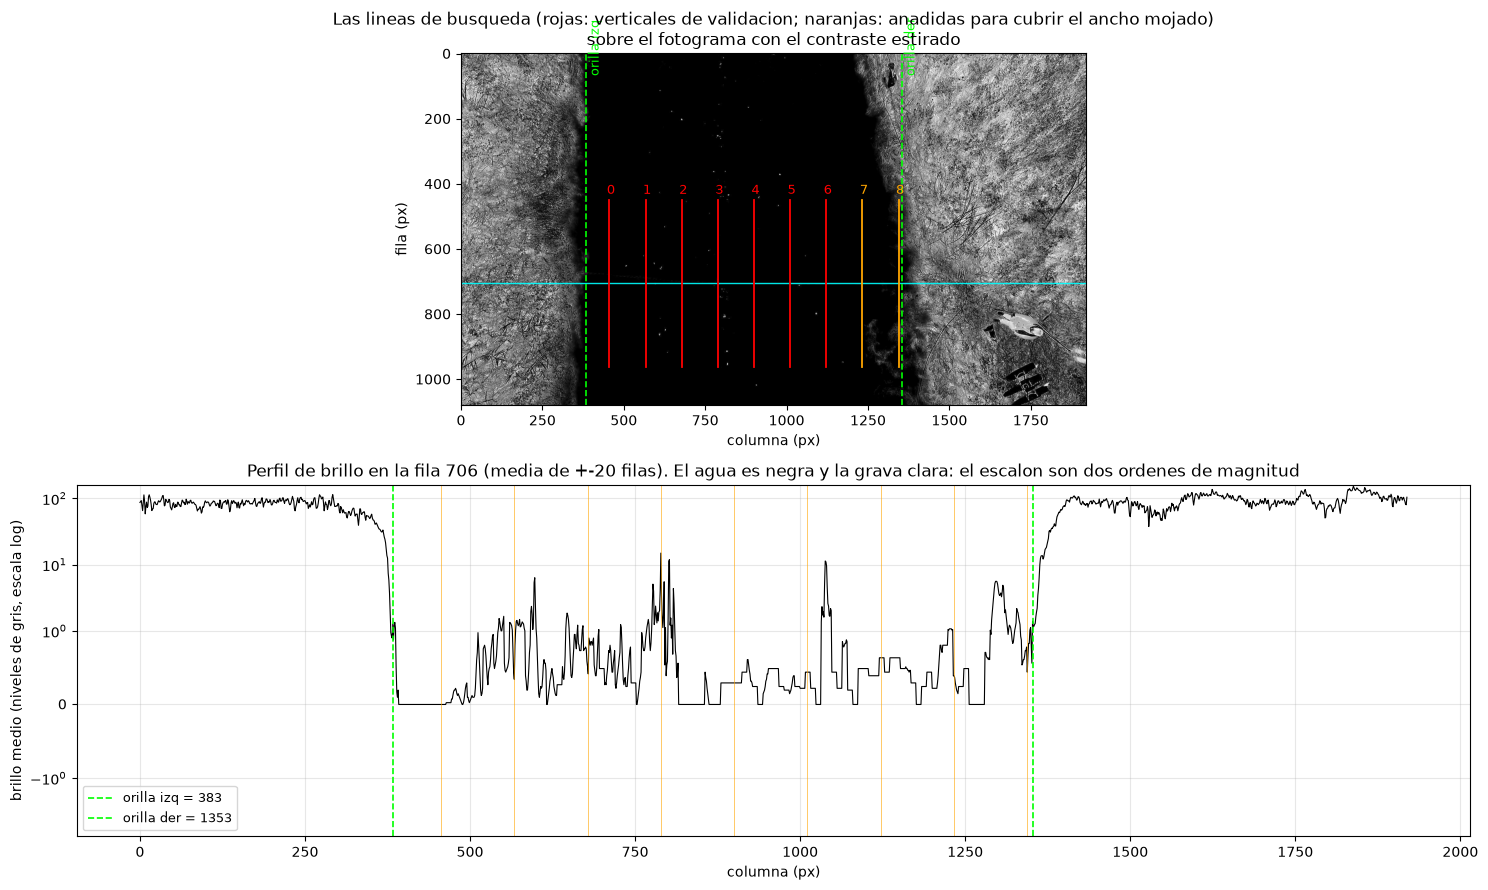

In [4]:
# Comprobacion de la geometria. Las coordenadas de las verticales se leen del fichero de
# validacion, pero SOLO las coordenadas: la columna de velocidades no se toca hasta la Parte 7.
_val = pd.read_excel(ARCHIVO_VALIDACION, header=None)
_fil = _val[_val[0].astype(str).str.startswith("Vert")]
COLUMNAS_VALIDACION = _fil[1].astype(int).to_numpy()
FILAS_VALIDACION = _fil[2].astype(int).to_numpy()
print("Verticales de validacion del dataset (solo posiciones):")
print(f"  columnas {COLUMNAS_VALIDACION.tolist()}")
print(f"  filas    {FILAS_VALIDACION.tolist()}   (todas en la fila de la seccion)")

# Perfil de brillo promediado sobre una banda de +-20 filas alrededor de la seccion, en el
# primer fotograma. Es la figura con la que se comprueban COLUMNA_AGUA_IZQ y COLUMNA_AGUA_DER.
banda = frame_gris[FILA_SECCION - 20:FILA_SECCION + 21].mean(axis=0)

fig = plt.figure(figsize=(15, 9))

ax = fig.add_subplot(2, 1, 1)
ax.imshow(frame_realce, cmap="gray")
ax.axhline(FILA_SECCION, color="cyan", lw=1.0, alpha=0.9)
for i, c in enumerate(columnas_estaciones):
    es_validacion = c in COLUMNAS_VALIDACION
    color = "red" if es_validacion else "orange"
    ax.plot([c, c], [FILA_SECCION - 256, FILA_SECCION + 256], color=color, lw=1.3)
    ax.text(c - 8, FILA_SECCION - 275, str(i), color=color, fontsize=9)
for c, etq in [(COLUMNA_AGUA_IZQ, "orilla izq"), (COLUMNA_AGUA_DER, "orilla der")]:
    ax.axvline(c, color="lime", ls="--", lw=1.2)
    ax.text(c + 6, 60, etq, color="lime", fontsize=9, rotation=90)
ax.set_title("Las lineas de busqueda (rojas: verticales de validacion; naranjas: anadidas para "
             "cubrir el ancho mojado)\nsobre el fotograma con el contraste estirado")
ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")

ax = fig.add_subplot(2, 1, 2)
ax.plot(banda, color="k", lw=0.8)
ax.axvline(COLUMNA_AGUA_IZQ, color="lime", ls="--", lw=1.2, label=f"orilla izq = {COLUMNA_AGUA_IZQ}")
ax.axvline(COLUMNA_AGUA_DER, color="lime", ls="--", lw=1.2, label=f"orilla der = {COLUMNA_AGUA_DER}")
for c in columnas_estaciones:
    ax.axvline(c, color="orange", lw=0.7, alpha=0.6)
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xlabel("columna (px)"); ax.set_ylabel("brillo medio (niveles de gris, escala log)")
ax.set_title(f"Perfil de brillo en la fila {FILA_SECCION} (media de +-20 filas). "
             "El agua es negra y la grava clara: el escalon son dos ordenes de magnitud")
ax.grid(alpha=0.3); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Construccion de las imagenes espacio-temporales

### El paso de muestreo

La STI **no** se lee pixel a pixel: se muestrea la linea cada $\Delta s$ pixeles, y esa eleccion
fija el angulo de las estelas. Con la escala y la cadencia de este video, el agua avanza

$$ d = \frac{u\,\Delta t}{e} \approx \frac{0.9 \times 0.0417}{0.009} \approx 4\ \text{px por fotograma} $$

Si se leyera un pixel por muestra, las estelas quedarian a $\arctan(4) = 76^\circ$. Muestreando
cada $\Delta s$ pixeles la pendiente en unidades de la STI es $m = d/\Delta s$, y derivando
$u \propto \tan\theta$:

$$ \frac{\delta u}{u} = \frac{\delta\theta}{\sin\theta\,\cos\theta} $$

el denominador es maximo en $\theta = 45^\circ$, o sea $m = 1$. La regla queda trivial:

$$ \boxed{\;\Delta s = d\;} $$

A $76^\circ$ el mismo error de angulo pesaria 4 veces mas que a $45^\circ$. Por eso la
configuracion pide `V_ESPERADA` y no $\Delta s$ directamente: es mas facil estimar una velocidad
que un paso de muestreo. La curva es plana cerca del optimo, asi que equivocarse un 30 % en
`V_ESPERADA` apenas cambia el resultado.

### La banda, que es la decision propia de este caso

En los otros casos del workspace la linea de busqueda es **una** linea. Aqui no funciona, y la
razon es el trazador. El agua del Bradano sale negra y lo unico visible son particulas sueltas;
una columna de un pixel de ancho pasa la mayor parte de los 25 s sin ninguna encima, y el tensor
se queda sin textura que orientar.

La solucion es muestrear una **banda** de lineas paralelas, normalizar cada STI por separado y
promediarlas. Cada linea aporta las pocas particulas que le tocan y la suma tiene estelas
continuas. Que funciona esta medido: con la misma configuracion en todo lo demas, la coherencia
mediana de las estaciones centrales sube asi al ensanchar la banda:

| ancho de banda | 0 px (una linea) | 12 px | 24 px | 40 px |
|---|---|---|---|---|
| estacion en x=567 | 0.47 | 0.69 | **0.76** | 0.84 |
| estacion en x=678 | 0.77 | 0.91 | **0.93** | 0.89 |
| estacion en x=900 | 0.80 | 0.93 | **0.94** | 0.95 |
| estacion en x=1011 | 0.71 | 0.87 | **0.90** | 0.91 |

Se elige **24 px** y no 40 porque la banda promedia *a traves* de la seccion, que es la direccion
en la que se quiere resolver el perfil: 24 px son 0.216 m, un 22 % de la separacion entre
estaciones, mientras que 40 px serian un 36 %. La ganancia entre 24 y 40 es marginal y el coste en
resolucion transversal no lo es.

Es importante ver que esto **no** es lo mismo que ensanchar el filtro antialias. El filtro
gaussiano se aplica antes de muestrear y promedia *intensidades*, borrando las particulas debiles
junto con el ruido. La banda promedia *STI ya normalizadas*, o sea que cada linea contribuye con su
estructura temporal a igualdad de peso, independientemente de lo brillante que sea.

### El filtro antialias

Tomar una muestra cada 4 px de una textura cuyos detalles miden pocos pixeles es submuestrear, y
eso produce **aliasing**: estructuras falsas con orientaciones inventadas. Como en cualquier
remuestreo, antes hay que filtrar paso bajo con

$$ \sigma = \tfrac{1}{2}\,\Delta s $$

El filtro es **isotropo a proposito**, igual que en el caso del Sile Main Canal.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Muestreo de la STI
# ---------------------------------------------------------------------------------------
# Orden de magnitud de la velocidad superficial. No es un resultado ni un dato de
# validacion: sale de correlar por fase parches de agua entre fotogramas consecutivos, que
# es la estimacion a ojo que daria cualquiera con el rio delante. De aqui sale DS.
V_ESPERADA = 0.9              # m/s

# Fotogramas a procesar. Se usa el video entero: 600 fotogramas son los 25 s completos.
# Con un trazador tan disperso, mas tiempo es mas particulas por linea, que es justo lo que
# escasea, y el coste de memoria de STIV no crece con la duracion.
N_FRAMES = 600

# Longitud de cada linea de busqueda, en muestras. 128 muestras a DS px son ~4.6 m de rio.
LARGO_STI = 128

# Ancho de la banda de lineas paralelas y separacion entre ellas, en pixeles. Ver la tabla
# de arriba: sin banda el caso no sale. 24 px = 0.216 m, un 22 % de la separacion entre
# estaciones.
ANCHO_BANDA = 24
PASO_BANDA = 4
# ---------------------------------------------------------------------------------------

D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))
SIGMA_ANTIALIAS = 0.5 * DS

offsets_banda = np.arange(-ANCHO_BANDA / 2, ANCHO_BANDA / 2 + 1e-9, PASO_BANDA)
N_BANDA = len(offsets_banda)

print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma")
print(f"  -> paso de muestreo  DS    = {DS} px  ({DS*ESCALA*100:.2f} cm)")
print(f"  -> filtro antialias  SIGMA = {SIGMA_ANTIALIAS:.1f} px  ({SIGMA_ANTIALIAS*ESCALA*100:.2f} cm)")
print(f"  -> estelas a {np.degrees(np.arctan(D_ESPERADO/DS)):.1f} grados")
print(f"\nBanda: {N_BANDA} lineas paralelas separadas {PASO_BANDA} px "
      f"(offsets {offsets_banda.tolist()})")
print(f"Cada linea: {LARGO_STI} muestras x {DS} px = {LARGO_STI*DS} px = "
      f"{LARGO_STI*DS*ESCALA:.2f} m de rio")


def mapa_banda(columnas, fila, angulo_deg, ds, largo, offsets):
    """Coordenadas de muestreo de todas las lineas de todas las estaciones.

    Devuelve mapx, mapy de forma (n_estaciones * n_banda, largo), que es lo que `cv2.remap`
    consume de una vez: un solo remap por fotograma resuelve la banda entera.
    """
    ang = np.radians(angulo_deg)
    ux, uy = np.cos(ang), np.sin(ang)        # a lo largo de la linea (direccion del flujo)
    px, py = -uy, ux                         # perpendicular (a traves de la seccion)
    s = (np.arange(largo) - largo / 2) * ds

    mx, my = [], []
    for c in columnas:
        for off in offsets:
            mx.append(c + off * px + s * ux)
            my.append(fila + off * py + s * uy)
    return np.array(mx, np.float32), np.array(my, np.float32)


mapx, mapy = mapa_banda(columnas_estaciones, FILA_SECCION, ANGULO_FLUJO,
                        DS, LARGO_STI, offsets_banda)
print(f"\nMapa de muestreo: {mapx.shape[0]} lineas x {mapx.shape[1]} muestras")
print(f"Recorrido en filas: {mapy.min():.0f} a {mapy.max():.0f} "
      f"(la imagen tiene {ALTO_PX})")

Desplazamiento esperado: 4.17 px/fotograma
  -> paso de muestreo  DS    = 4 px  (3.60 cm)
  -> filtro antialias  SIGMA = 2.0 px  (1.80 cm)
  -> estelas a 46.2 grados

Banda: 7 lineas paralelas separadas 4 px (offsets [-12.0, -8.0, -4.0, 0.0, 4.0, 8.0, 12.0])
Cada linea: 128 muestras x 4 px = 512 px = 4.61 m de rio

Mapa de muestreo: 63 lineas x 128 muestras
Recorrido en filas: 454 a 962 (la imagen tiene 1080)


In [6]:
def construir_sti(ruta_video, n_frames, mapx, mapy, sigma):
    """Una sola pasada sobre el video. Devuelve (n_frames, n_lineas, largo).

    Nunca hay mas de un fotograma vivo: se lee, se filtra, se muestrea y se tira. Es la razon
    de que el consumo de memoria de STIV no dependa de la duracion del video.
    """
    cap = cv2.VideoCapture(str(ruta_video))
    filas = []
    for _ in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        suave = cv2.GaussianBlur(gris, (0, 0), sigma)
        filas.append(cv2.remap(suave, mapx, mapy, cv2.INTER_LINEAR,
                               borderMode=cv2.BORDER_REPLICATE))
    cap.release()
    return np.stack(filas)


with benchmark.medir("Parte 3: leer el video y construir las STI",
                     n_frames=N_FRAMES, lineas=int(mapx.shape[0])):
    sti_banda = construir_sti(ARCHIVO_VIDEO, N_FRAMES, mapx, mapy, SIGMA_ANTIALIAS)

N_LEIDOS = sti_banda.shape[0]
# (t, estacion*banda, muestra) -> (estacion, t, banda, muestra)
sti_banda = sti_banda.reshape(N_LEIDOS, N_ESTACIONES, N_BANDA, LARGO_STI).transpose(1, 0, 2, 3)

# El brillo medio de cada estacion, ANTES de normalizar nada. Es la magnitud con la que la
# Parte 4b distingue el agua de la orilla, y hay que guardarla ahora porque la preparacion
# de la STI la elimina por construccion.
brillo_estacion = sti_banda.mean(axis=(1, 2, 3))

print(f"Fotogramas leidos: {N_LEIDOS} de {N_FRAMES} pedidos")
print(f"STI por estacion: {N_LEIDOS} x {LARGO_STI} (x {N_BANDA} lineas de banda)")
print(f"Memoria de todas las STI: {sti_banda.nbytes/1e6:.1f} MB")

  [bench] Parte 3: leer el video y construir las STI: 62.9 s | CPU 73.1 s (1.2 nucleos) | RAM pico 268 MB
Fotogramas leidos: 600 de 600 pedidos
STI por estacion: 600 x 128 (x 7 lineas de banda)
Memoria de todas las STI: 19.4 MB


### Preparacion de la STI

La STI recien construida no se puede meter directamente en el tensor: contiene dos cosas que no
son la senal y que dominarian el resultado.

1. **El fondo estatico.** Cada muestra tiene su propio brillo medio. En la STI eso son **rayas
   verticales** perfectas, que el tensor leeria como "velocidad cero" con muchisima energia. Se
   quita restando la media temporal de cada muestra:

   $$ A[k,j] = \mathrm{STI}[k,j] - \frac{1}{N_t}\sum_{k'} \mathrm{STI}[k',j] $$

2. **El parpadeo global.** Si un fotograma entero sale mas claro, eso son **rayas horizontales**,
   que el tensor leeria como velocidad infinita. Se quita restando la media espacial de cada
   fotograma.

Por ultimo se divide por la desviacion tipica global. Aqui esa division tiene una funcion extra:
es lo que permite **promediar las lineas de la banda entre si**. Sin ella, una linea que casualmente
tenga una particula muy brillante dominaria la media y las demas no contarian; normalizando
primero, las siete lineas entran con el mismo peso y lo que se suma son estructuras temporales, no
intensidades.

  [bench] Parte 3b: preparar y promediar la banda: 0.2 s | CPU 0.2 s (0.9 nucleos) | RAM pico 230 MB
STI preparadas: (9, 600, 128)


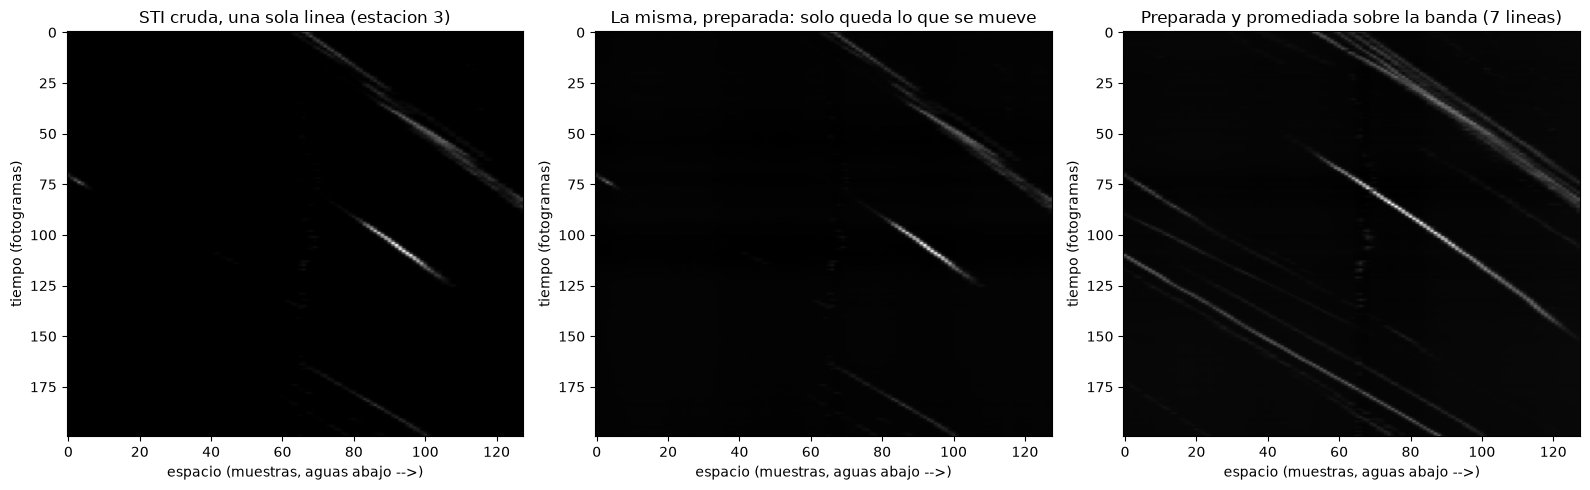

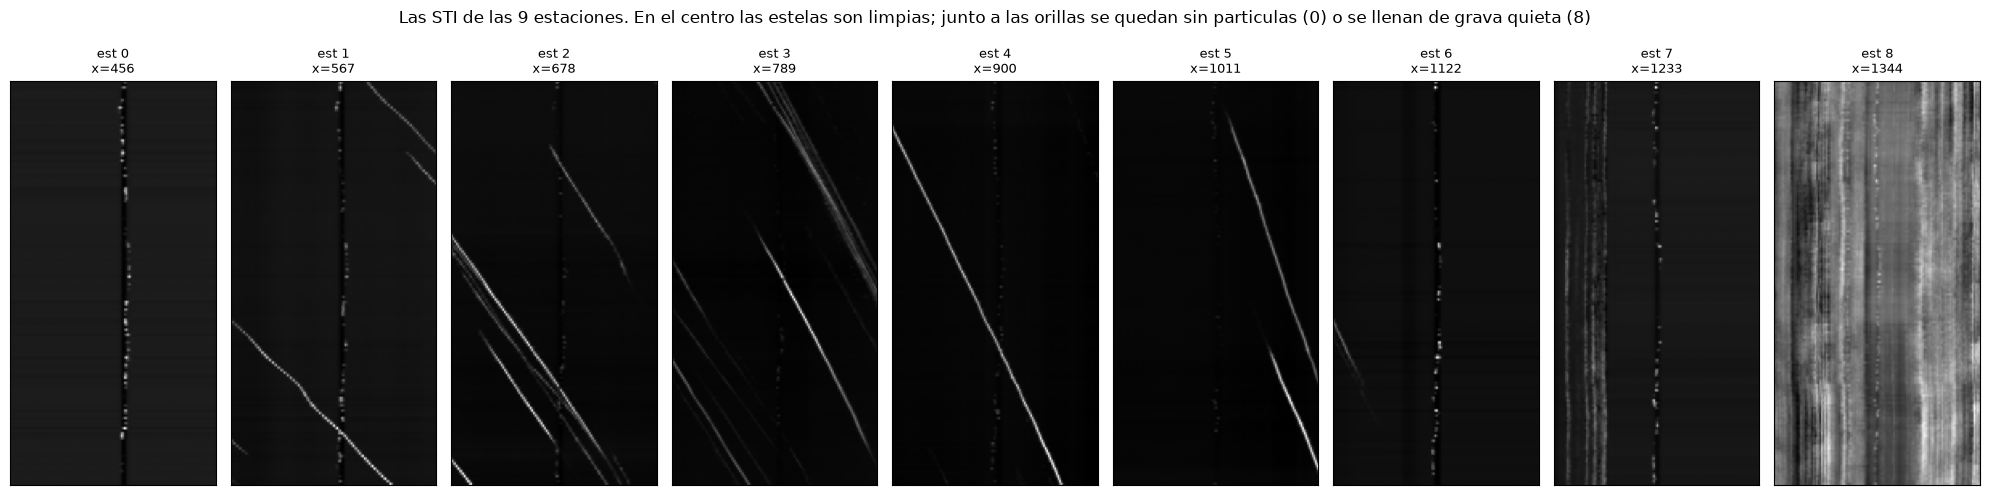

In [7]:
def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # 1) fondo fijo de cada muestra
    a = a - a.mean(axis=1, keepdims=True)       # 2) parpadeo de cada fotograma
    d = a.std()
    return a / d if d > 0 else a


with benchmark.medir("Parte 3b: preparar y promediar la banda", lineas=N_ESTACIONES):
    # Cada linea de la banda se normaliza por separado y luego se promedian: ese orden es el
    # que iguala los pesos. Hacerlo al reves seria promediar intensidades.
    sti_prep = np.stack([
        np.mean([preparar_sti(sti_banda[i, :, b, :]) for b in range(N_BANDA)], axis=0)
        for i in range(N_ESTACIONES)
    ])

print(f"STI preparadas: {sti_prep.shape}")

# Efecto de la preparacion y de la banda sobre una estacion central.
i_demo = 3
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(sti_banda[i_demo, :200, N_BANDA // 2, :], cmap="gray", aspect="auto")
axes[0].set_title(f"STI cruda, una sola linea (estacion {i_demo})")
axes[1].imshow(preparar_sti(sti_banda[i_demo, :, N_BANDA // 2, :])[:200], cmap="gray", aspect="auto")
axes[1].set_title("La misma, preparada: solo queda lo que se mueve")
axes[2].imshow(sti_prep[i_demo][:200], cmap="gray", aspect="auto")
axes[2].set_title(f"Preparada y promediada sobre la banda ({N_BANDA} lineas)")
for ax in axes:
    ax.set_xlabel("espacio (muestras, aguas abajo -->)")
    ax.set_ylabel("tiempo (fotogramas)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_preparacion_sti.png", dpi=110, bbox_inches="tight")
plt.show()

# Todas las estaciones, para ver como se degradan las estelas al acercarse a las orillas.
fig, axes = plt.subplots(1, N_ESTACIONES, figsize=(20, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(sti_prep[i][:160], cmap="gray", aspect="auto")
    ax.set_title(f"est {i}\nx={columnas_estaciones[i]}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Las STI de las 9 estaciones. En el centro las estelas son limpias; junto a las "
             "orillas se quedan sin particulas (0) o se llenan de grava quieta (8)", fontsize=12)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_todas_las_sti.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidad con el tensor de estructura

Solo queda medir la orientacion dominante de las estelas. La herramienta estandar para eso es el
**tensor de estructura del gradiente**.

Sobre la STI preparada se calculan las dos derivadas parciales, en espacio y en tiempo:

$$ I_x = \frac{\partial B}{\partial x}, \qquad I_t = \frac{\partial B}{\partial t} $$

(con un operador de Sobel de 3x3, precedido de un suavizado gaussiano leve). Con ellas se forma la
matriz simetrica 2x2

$$ J \;=\; \begin{pmatrix} \sum I_x^2 & \sum I_x I_t \\[2pt] \sum I_x I_t & \sum I_t^2 \end{pmatrix} $$

El gradiente de una estela apunta **perpendicular** a ella, asi que el autovector del autovalor
**menor** apunta **a lo largo** de las estelas. Si ese autovector es $(e_x, e_t)$, la pendiente es

$$ m = \frac{e_x}{e_t} \qquad \text{[muestras de espacio por fotograma]} $$

y la velocidad

$$ u = m\,\frac{\Delta s \cdot e}{\Delta t} $$

$m$ sale **con signo**, asi que el metodo distingue tambien el sentido del flujo: aqui no se impone
que el rio baje o suba, se mide.

### La coherencia

El tensor viene con una medida de calidad gratis:

$$ C \;=\; \frac{\lambda_1 - \lambda_2}{\lambda_1 + \lambda_2}
      \;=\; \frac{\sqrt{(J_{xx}-J_{tt})^2 + 4J_{xt}^2}}{J_{xx}+J_{tt}} \;\in[0,1] $$

$C = 1$ significa que toda la textura apunta en la misma direccion; $C = 0$, que no hay direccion
privilegiada. $C = 0.7$ equivale a $\lambda_1/\lambda_2 \approx 5.7$.

### Por bloques, no de una vez

Resolver un solo tensor sobre la STI entera deja que una zona brillante decida la respuesta de
toda la estacion. Se resuelve por **bloques de 64x64 con 50 % de solape**, y se combinan por una
**mediana ponderada por coherencia**: cada bloque vota con el peso de lo seguro que esta. Con 600
fotogramas y 128 muestras salen 51 bloques por estacion.

Que esto importa esta medido en este mismo video: con un unico tensor global la estacion central
daba coherencia 0.77 y una velocidad de 0.99 m/s; por bloques con mediana ponderada da 0.76 y
**1.38 m/s**, que es la que reproduce el pico del perfil.

In [8]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Parametros del estimador
# ---------------------------------------------------------------------------------------
# Lado del bloque de STI sobre el que se resuelve un tensor, en pixeles de STI. Con los
# valores de este caso, 64 px son ~2.7 s de tiempo y ~2.3 m de rio.
LADO_BLOQUE = 64

# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50

# Suavizado gaussiano previo a las derivadas de Sobel, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    g = cv2.GaussianBlur(bloque, (0, 0), sigma)
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    # se recorta el borde: Sobel contamina 2 px por el efecto de borde
    It, Ix = It[2:-2, 2:-2], Ix[2:-2, 2:-2]

    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0

    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def mediana_ponderada(valores, pesos):
    """Mediana de `valores` ponderada por `pesos`. Sin dependencias."""
    orden = np.argsort(valores)
    v, w = np.asarray(valores)[orden], np.asarray(pesos)[orden]
    return float(v[np.searchsorted(np.cumsum(w), 0.5 * w.sum())])


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE):
    """Pendiente robusta de una STI completa, por bloques con solape."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado])
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0, 0, 0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana, 0, len(ms)
    return mediana_ponderada(ms[usables], cs[usables]), coh_mediana, int(usables.sum()), len(ms)


def pendiente_a_velocidad(m):
    """m [muestras/fotograma] -> u [m/s]. El signo indica el sentido a lo largo de la linea."""
    return m * DS * ESCALA / DT

In [9]:
v_stiv = np.full(N_ESTACIONES, np.nan)
coherencia = np.full(N_ESTACIONES, np.nan)
bloques_ok = np.zeros(N_ESTACIONES, int)
bloques_tot = np.zeros(N_ESTACIONES, int)

with benchmark.medir("Parte 4: tensor de estructura en todas las estaciones",
                     lineas=N_ESTACIONES):
    for i in range(N_ESTACIONES):
        m, c, nok, ntot = medir_sti(sti_prep[i])
        v_stiv[i] = pendiente_a_velocidad(m) if np.isfinite(m) else np.nan
        coherencia[i] = c
        bloques_ok[i], bloques_tot[i] = nok, ntot

# El signo dice el sentido del flujo a lo largo de la linea. ANGULO_FLUJO apunta hacia
# arriba en la imagen, y el rio va hacia arriba, asi que las velocidades salen positivas;
# el modulo es lo que se compara con la referencia.
resultados = pd.DataFrame({
    "estacion": np.arange(N_ESTACIONES),
    "columna_px": columnas_estaciones,
    "s_m": s_estaciones.round(3),
    "v_stiv_ms": np.abs(v_stiv),
    "signo": np.where(np.isfinite(v_stiv), np.sign(v_stiv), np.nan),
    "coherencia": coherencia,
    "brillo": brillo_estacion.round(3),
    "bloques": [f"{a}/{b}" for a, b in zip(bloques_ok, bloques_tot)],
})
print(resultados.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))
print(f"\nSentido medido: {'aguas arriba en la imagen' if np.nanmedian(v_stiv) > 0 else 'aguas abajo en la imagen'}"
      "  (no se impuso: sale del signo del tensor)")

  [bench] Parte 4: tensor de estructura en todas las estaciones: 0.3 s | CPU 0.2 s (0.7 nucleos) | RAM pico 241 MB
 estacion  columna_px      s_m  v_stiv_ms    signo  coherencia   brillo bloques
        0         456   0.6570     0.0039   1.0000      0.2441   0.0130    2/34
        1         567   1.6560     1.3836   1.0000      0.7567   0.2330   31/51
        2         678   2.6550     0.9546   1.0000      0.9148   0.1260   40/51
        3         789   3.6540     0.7270   1.0000      0.9717   0.4230   49/51
        4         900   4.6530     0.5912   1.0000      0.9373   0.2070   48/51
        5        1011   5.6520     0.4627   1.0000      0.8972   0.1210   45/51
        6        1122   6.6510     0.1574   1.0000      0.5277   0.0290   26/51
        7        1233   7.6500     0.0063   1.0000      0.5430   0.1620   28/51
        8        1344   8.6490     0.0051  -1.0000      0.8184  12.3420   51/51

Sentido medido: aguas arriba en la imagen  (no se impuso: sale del signo del tensor)

---
## Parte 4b - Control de calidad

Paso imprescindible, y el equivalente del filtrado de mascaras de un flujo LSPIV. Aqui hacen falta
**dos** criterios, porque este caso tiene dos modos de fallo distintos y ninguno de los dos los
detecta el otro.

### 1. Coherencia: la estacion no tiene estelas

Las estaciones pegadas a las orillas quedan en sombra del talud y practicamente no reciben
particulas. Su STI es ruido, y la coherencia lo dice.

### 2. Brillo: la estacion no esta mirando al agua

Este es el que importa, y es la leccion que dejo el caso de Boneyard Creek: **una estructura
estatica da una estela perfectamente coherente de pendiente cero**. La estacion 8 de este notebook
esta a 9 px de la orilla derecha, su banda pisa la grava, y devuelve **coherencia 0.82 con
velocidad 0.00 m/s**. Un umbral de coherencia la *acepta*: 0.82 esta muy por encima de 0.70.

En Boneyard el discriminante fue el **contraste temporal**, porque alli el agua tenia textura movil
y el muro no. Aqui eso no vale: la orilla de grava es la que mas contraste temporal tiene de todo
el fotograma (2.52 niveles de gris frente a 0.03-1.89 en el agua), porque es clara y le afecta el
ruido de compresion. El discriminante limpio aqui es el **brillo**, y por la misma razon que hacia
facil la Parte 2: el agua del Bradano es negra y la grava no.

Medido sobre las nueve estaciones, el brillo medio de la STI vale **0.013 a 0.42** en las que estan
sobre agua y **12.59** en la que pisa la orilla. Es un factor 30, con dos ordenes de magnitud de
margen para poner el umbral. `BRILLO_MAX_AGUA = 5.0` esta en mitad del hueco.

### Lo que no se hace: rellenar

Las estaciones rechazadas **no se rellenan**. En el caso del Sile Main Canal si se rellenan, porque
alli hay que integrar un caudal y un hueco en la seccion es un trozo de caudal que falta. Aqui no
se integra nada -- el dataset no publica batimetria, asi que no hay area y no hay caudal -- y en
ese caso rellenar solo seria inventar datos. Es el mismo criterio que en Boneyard Creek.

In [10]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una estacion. 0.70 equivale a que la
# orientacion dominante sea ~6 veces mas fuerte que la perpendicular. Es el mismo valor que
# usa el caso del Sile Main Canal, y se fija ANTES de ver ningun resultado.
COH_MIN_ESTACION = 0.70

# Brillo medio maximo de la STI para considerar que la estacion mira al agua y no a la
# orilla. Ver arriba: agua 0.01-0.42, grava 12.59. El umbral esta en mitad del hueco.
BRILLO_MAX_AGUA = 5.0
# ---------------------------------------------------------------------------------------

sobre_agua = brillo_estacion <= BRILLO_MAX_AGUA
tiene_estelas = (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)
valida = sobre_agua & tiene_estelas

resultados["estado"] = [
    "valida" if valida[i] else ("ORILLA" if not sobre_agua[i] else "SIN ESTELAS")
    for i in range(N_ESTACIONES)
]
v_final = np.where(valida, np.abs(v_stiv), np.nan)
resultados["v_final_ms"] = v_final

print(f"Estaciones validas: {valida.sum()} de {N_ESTACIONES}\n")
for i in range(N_ESTACIONES):
    if not valida[i]:
        motivo = ("brillo %.2f > %.1f: la banda pisa la orilla" % (brillo_estacion[i], BRILLO_MAX_AGUA)
                  if not sobre_agua[i] else
                  "coherencia %.2f < %.2f: sin estelas utilizables" % (coherencia[i], COH_MIN_ESTACION))
        print(f"  Estacion {i} (x={columnas_estaciones[i]}, s={s_estaciones[i]:.2f} m) "
              f"RECHAZADA -> {motivo}")

print("\nEl caso de la estacion 8 es el que justifica el segundo criterio:")
print(f"  coherencia {coherencia[8]:.3f} (pasaria el umbral de {COH_MIN_ESTACION}), "
      f"velocidad {abs(v_stiv[8]):.3f} m/s, brillo {brillo_estacion[8]:.2f}")
print("  Una orilla quieta es una estela perfectamente coherente de pendiente cero.")

print()
print(resultados[["estacion", "columna_px", "s_m", "v_stiv_ms", "coherencia",
                  "brillo", "estado"]].to_string(index=False,
                                                 float_format=lambda x: f"{x:8.4f}"))

Estaciones validas: 5 de 9

  Estacion 0 (x=456, s=0.66 m) RECHAZADA -> coherencia 0.24 < 0.70: sin estelas utilizables
  Estacion 6 (x=1122, s=6.65 m) RECHAZADA -> coherencia 0.53 < 0.70: sin estelas utilizables
  Estacion 7 (x=1233, s=7.65 m) RECHAZADA -> coherencia 0.54 < 0.70: sin estelas utilizables
  Estacion 8 (x=1344, s=8.65 m) RECHAZADA -> brillo 12.34 > 5.0: la banda pisa la orilla

El caso de la estacion 8 es el que justifica el segundo criterio:
  coherencia 0.818 (pasaria el umbral de 0.7), velocidad 0.005 m/s, brillo 12.34
  Una orilla quieta es una estela perfectamente coherente de pendiente cero.

 estacion  columna_px      s_m  v_stiv_ms  coherencia   brillo      estado
        0         456   0.6570     0.0039      0.2441   0.0130 SIN ESTELAS
        1         567   1.6560     1.3836      0.7567   0.2330      valida
        2         678   2.6550     0.9546      0.9148   0.1260      valida
        3         789   3.6540     0.7270      0.9717   0.4230      valida
    

---
## Parte 5 - El perfil transversal

Aqui termina la medida. **Este notebook no calcula un caudal, y no es una limitacion del metodo
sino del dataset**: el release del Bradano publica el video, su escala y siete velocidades de
referencia, y nada mas. No hay batimetria, no hay seccion transversal, no hay calados. Sin
profundidades no hay area, y sin area no hay caudal. Inventar una seccion rectangular para poder
escribir un numero en m3/s daria una cifra cuya incertidumbre estaria dominada por completo por la
profundidad supuesta, no por la velocidad medida, que es lo unico que este notebook sabe.

Es la misma situacion que en Boneyard Creek, con una diferencia a favor: alli tampoco habia
**longitudes**, asi que la velocidad salia en unidades afines (alturas de camara por segundo).
Aqui el dataset da la escala, de modo que el resultado esta en **m/s de verdad**.

Lo que si se puede componer es el perfil transversal de velocidad superficial, que es el
observable que el dataset pide comparar.

  [bench] Parte 5: perfil transversal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 241 MB
Estaciones medidas: 5 de 9
Velocidad superficial mediana sobre las medidas: 0.7270 m/s
Rango medido: 0.4627 a 1.3836 m/s


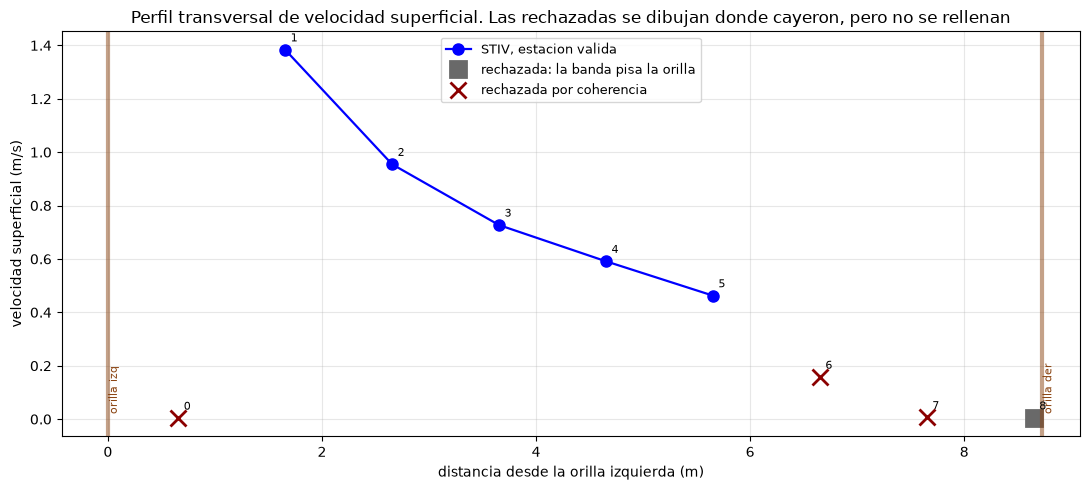

In [11]:
with benchmark.medir("Parte 5: perfil transversal"):
    v_mediana = float(np.nanmedian(v_final))
    v_media = float(np.nanmean(v_final))

print(f"Estaciones medidas: {int(valida.sum())} de {N_ESTACIONES}")
print(f"Velocidad superficial mediana sobre las medidas: {v_mediana:.4f} m/s")
print(f"Rango medido: {np.nanmin(v_final):.4f} a {np.nanmax(v_final):.4f} m/s")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(s_estaciones[valida], v_final[valida], "b-o", ms=8, lw=1.6, label="STIV, estacion valida")
for motivo, mascara, marca, color, etq in [
    ("orilla", ~sobre_agua, "s", "dimgray", "rechazada: la banda pisa la orilla"),
    ("estelas", sobre_agua & ~tiene_estelas, "x", "darkred", "rechazada por coherencia"),
]:
    if mascara.any():
        ax.plot(s_estaciones[mascara], np.abs(v_stiv)[mascara], marca, color=color,
                ms=11, mew=2, label=etq)
for c, etq in [(0.0, "orilla izq"), ((COLUMNA_AGUA_DER - COLUMNA_AGUA_IZQ) * ESCALA, "orilla der")]:
    ax.axvline(c, color="saddlebrown", lw=3, alpha=0.5)
    ax.text(c, ax.get_ylim()[1] * 0.02, etq, rotation=90, fontsize=8, color="saddlebrown")
for i in range(N_ESTACIONES):
    ax.annotate(str(i), (s_estaciones[i], np.nan_to_num(np.abs(v_stiv)[i])),
                fontsize=8, xytext=(4, 6), textcoords="offset points")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad superficial (m/s)")
ax.set_title("Perfil transversal de velocidad superficial. Las rechazadas se dibujan donde "
             "cayeron, pero no se rellenan")
ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_perfil.png", dpi=110, bbox_inches="tight")
plt.show()

### Las velocidades sobre el rio

El perfil de arriba, puesto donde se midio. Cada flecha es **una linea de busqueda entera**, no un
punto: STIV promedia a lo largo de los 512 px muestreados, asi que no hay campo 2D que dibujar
como en LSPIV. La direccion no se mide, se impone (`ANGULO_FLUJO`); lo que si sale del tensor es el
**sentido**, y apunta aguas arriba de la imagen, que es lo que hace el rio.

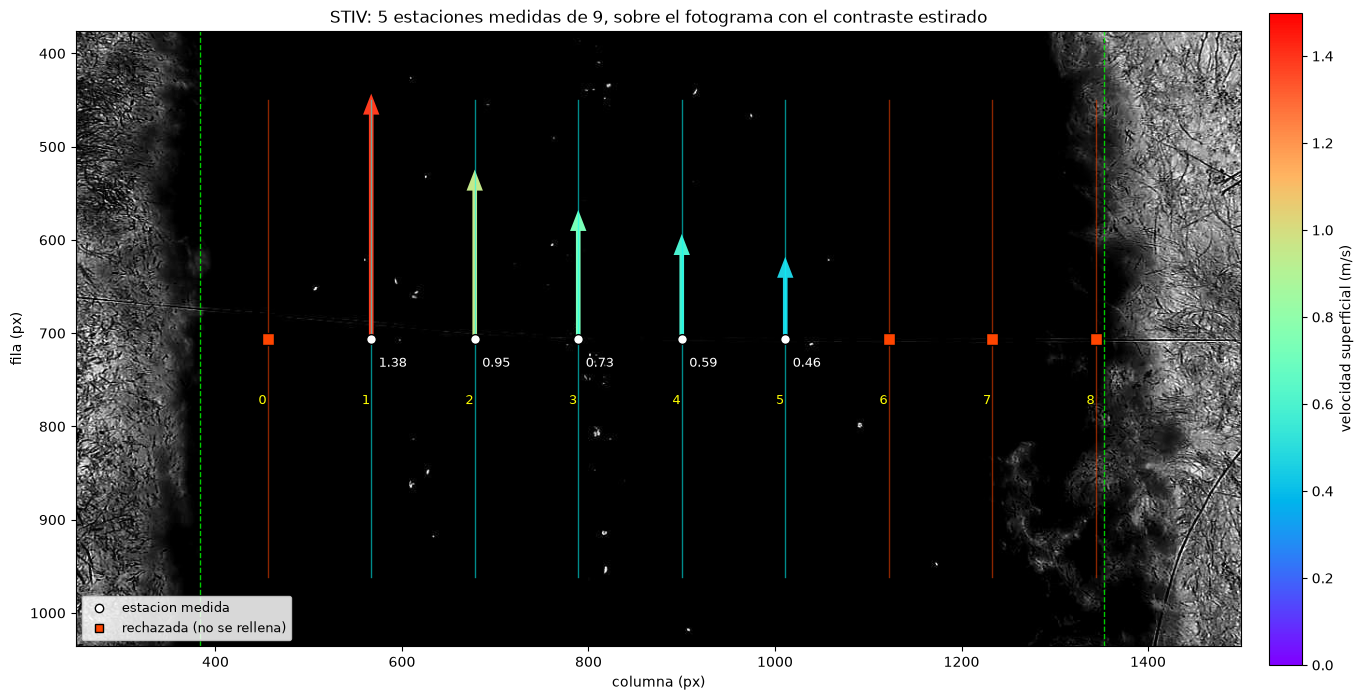

In [12]:
# Las velocidades medidas, dibujadas sobre el propio fotograma.
PX_POR_MS = 190          # pixeles de flecha por cada m/s, solo para que se vean

ang = np.radians(ANGULO_FLUJO)
signo = np.sign(np.nanmedian(v_stiv))
u = v_final * PX_POR_MS * np.cos(ang) * signo
w = v_final * PX_POR_MS * np.sin(ang) * signo

fig, ax = plt.subplots(figsize=(15, 9))
ax.imshow(frame_realce, cmap="gray")

# Las lineas de busqueda, tenues, para ver de donde sale cada flecha.
dxl = 0.5 * LARGO_STI * DS * np.cos(ang)
dyl = 0.5 * LARGO_STI * DS * np.sin(ang)
for i, c in enumerate(columnas_estaciones):
    color = "cyan" if valida[i] else "orangered"
    ax.plot([c - dxl, c + dxl], [FILA_SECCION - dyl, FILA_SECCION + dyl],
            color=color, lw=1.0, alpha=0.55)

medidas = np.where(valida)[0]
q = ax.quiver(columnas_estaciones[medidas], np.full(len(medidas), FILA_SECCION),
              u[medidas], w[medidas], v_final[medidas],
              cmap="rainbow", norm=plt.Normalize(vmin=0.0, vmax=1.5),
              angles="xy", scale_units="xy", scale=1,
              width=0.004, headwidth=3.5, headlength=4.5)
fig.colorbar(q, ax=ax, label="velocidad superficial (m/s)", pad=0.02, shrink=0.75)

for i, c in enumerate(columnas_estaciones):
    if valida[i]:
        ax.plot(c, FILA_SECCION, "o", color="w", ms=7, mec="k")
        ax.text(c + 8, FILA_SECCION + 30, f"{v_final[i]:.2f}", color="w", fontsize=9)
    else:
        ax.plot(c, FILA_SECCION, "s", color="orangered", ms=8, mec="k")
    ax.text(c - 10, FILA_SECCION + 70, f"{i}", color="yellow", fontsize=9)

ax.plot([], [], "o", color="w", mec="k", label="estacion medida")
ax.plot([], [], "s", color="orangered", mec="k", label="rechazada (no se rellena)")
ax.legend(loc="lower left", fontsize=9, framealpha=0.85)
ax.axvline(COLUMNA_AGUA_IZQ, color="lime", ls="--", lw=1.0, alpha=0.8)
ax.axvline(COLUMNA_AGUA_DER, color="lime", ls="--", lw=1.0, alpha=0.8)
ax.set_xlim(250, 1500); ax.set_ylim(FILA_SECCION + 330, FILA_SECCION - 330)
ax.set_title(f"STIV: {int(valida.sum())} estaciones medidas de {N_ESTACIONES}, sobre el "
             "fotograma con el contraste estirado")
ax.set_xlabel("columna (px)"); ax.set_ylabel("fila (px)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig6_vectores.png", dpi=130, bbox_inches="tight")
plt.show()

In [13]:
# Se congela la configuracion completa: es lo que hace reproducible el resultado.
config = dict(
    video=str(ARCHIVO_VIDEO), n_frames=int(N_LEIDOS), fps=round(FPS, 4),
    escala_m_px=ESCALA, fila_seccion=FILA_SECCION,
    columna_agua_izq=COLUMNA_AGUA_IZQ, columna_agua_der=COLUMNA_AGUA_DER,
    columna_estacion_0=COLUMNA_ESTACION_0, paso_estacion_px=PASO_ESTACION_PX,
    n_estaciones=N_ESTACIONES, angulo_flujo_grados=ANGULO_FLUJO,
    v_esperada_ms=V_ESPERADA, ds_px=DS, sigma_antialias_px=SIGMA_ANTIALIAS,
    largo_sti=LARGO_STI, ancho_banda_px=ANCHO_BANDA, paso_banda_px=PASO_BANDA,
    lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
    sigma_derivada=SIGMA_DERIVADA,
    coh_min_estacion=COH_MIN_ESTACION, brillo_max_agua=BRILLO_MAX_AGUA,
    v_superficial_mediana_ms=round(v_mediana, 6),
    estaciones_validas=int(valida.sum()),
)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")
resultados.to_csv(SALIDA_PERFIL, index=False)

print(f"Configuracion congelada en: {SALIDA_CONFIG}")
print(f"Perfil guardado en:         {SALIDA_PERFIL}")

Configuracion congelada en: salidas\config_stiv.json
Perfil guardado en:         salidas\perfil_velocidades.csv


---
## Parte 6 - Recursos consumidos

Cada bloque caro va envuelto en `benchmark.medir(...)`, que cronometra tiempo de reloj, tiempo de
CPU y memoria.

### Lo que hay que mirar

**El algoritmo no es lo caro.** El tensor de estructura, que es el corazon del metodo, trabaja
sobre 9 STI de 600x128 px -- 2.8 MB en total -- y se resuelve en decimas de segundo. Lo que cuesta
es **llegar hasta ahi**: decodificar 600 fotogramas de 1920x1080, pasarlos a gris y filtrarlos. Eso
se hace en una **unica pasada** sobre el video, que es todo lo que este notebook necesita.

Es la misma asimetria que miden los otros tres casos de STIV del workspace, y conviene tenerla
presente antes de optimizar nada: bajar la resolucion de lectura o recortar la region decodificada
si vale la pena; tocar el tensor no.

### El coste propio de este caso

La banda multiplica por siete el numero de muestras que hay que interpolar por fotograma, pero
**no** el numero de fotogramas ni de filtros gaussianos, que es donde esta el tiempo. Un solo
`cv2.remap` por fotograma resuelve las 63 lineas de una vez. La tabla deja ver que la banda sale
practicamente gratis comparada con la decodificacion.

Maquina donde se miden los tiempos:
  cpu_nucleos_fisicos: 8
  cpu_nucleos_logicos: 12
  ram_total_gb: 42.7
  ram_disponible_gb: 22.9

Tiempo total medido:         63.4 s
Pico de memoria del proceso: 268 MB
Fotogramas decodificados y filtrados: 600
  -> 105.6 ms por fotograma de media

Guardado en: salidas\benchmark_recursos.csv



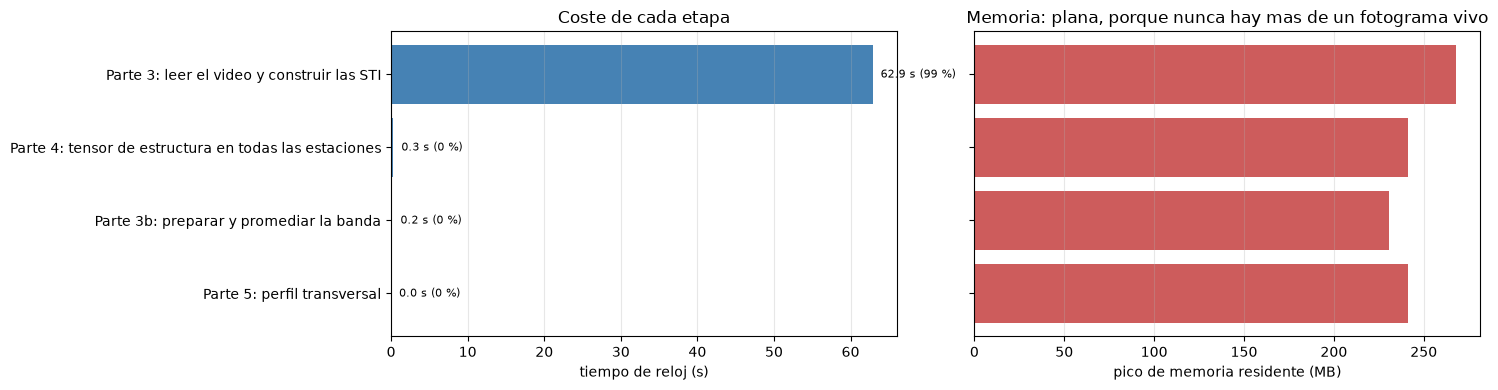

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,lineas,pct_tiempo
0,Parte 3: leer el video y construir las STI,62.88,73.06,1.16,267.9,21.1,600.0,63.0,99.2
1,Parte 3b: preparar y promediar la banda,0.18,0.16,0.85,230.5,0.7,NaN,9.0,0.3
2,Parte 4: tensor de estructura en todas las est...,0.30,0.22,0.73,241.3,0.2,NaN,9.0,0.5
3,Parte 5: perfil transversal,0.00,0.00,0.00,241.5,0.0,NaN,NaN,0.0


In [14]:
print("Maquina donde se miden los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)

total_s = tabla_recursos["segundos"].sum()
n_fot = max(benchmark.fotogramas_procesados(), 1)
print(f"\nTiempo total medido:         {total_s:.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")
print(f"Fotogramas decodificados y filtrados: {n_fot}")
print(f"  -> {1000*total_s/n_fot:.1f} ms por fotograma de media")
print(f"\nGuardado en: {SALIDA_BENCHMARK}\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
orden = tabla_recursos.sort_values("segundos")
axes[0].barh(orden["etapa"], orden["segundos"], color="steelblue")
axes[0].set_xlabel("tiempo de reloj (s)")
axes[0].set_title("Coste de cada etapa")
axes[0].grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    axes[0].text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)

axes[1].barh(orden["etapa"], orden["ram_pico_mb"], color="indianred")
axes[1].set_xlabel("pico de memoria residente (MB)")
axes[1].set_title("Memoria: plana, porque nunca hay mas de un fotograma vivo")
axes[1].grid(axis="x", alpha=0.3)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_recursos.png", dpi=110, bbox_inches="tight")
plt.show()

tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui **no se ha usado ni una sola velocidad de referencia**. De la hoja de validacion se
leyeron en la Parte 2 las columnas y filas de las siete verticales, que son geometria, igual que
en el caso del Sile Main Canal se leen las progresivas del CSV del aforo. La columna `Vel` se abre
ahora, por primera vez.

**Esta es la ultima parte del notebook con resultados. No se vuelve atras a ajustar nada.**

In [15]:
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera y unica vez que aparecen. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
V_REFERENCIA = _fil[3].astype(float).to_numpy()   # m/s, una por vertical Vert1..Vert7
# ---------------------------------------------------------------------------------------

# Cada vertical de validacion se empareja con la estacion que esta en su misma columna.
indice_estacion = {c: i for i, c in enumerate(columnas_estaciones)}
filas = []
for c, vref in zip(COLUMNAS_VALIDACION, V_REFERENCIA):
    i = indice_estacion[c]
    filas.append(dict(vertical=f"Vert{len(filas)+1}", estacion=i, columna_px=c,
                      s_m=round(s_estaciones[i], 3),
                      v_stiv=v_final[i], v_ref=vref,
                      coherencia=round(coherencia[i], 3), estado=resultados["estado"][i]))
comparacion = pd.DataFrame(filas)
comparacion["dif_ms"] = comparacion.v_stiv - comparacion.v_ref
comparacion["dif_pct"] = 100 * (comparacion.v_stiv / comparacion.v_ref - 1)

print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.3f}"))

emparejadas = comparacion.dropna(subset=["v_stiv"])
sesgo = float(emparejadas.dif_ms.mean())
rmse = float(np.sqrt((emparejadas.dif_ms ** 2).mean()))
r = float(np.corrcoef(emparejadas.v_stiv, emparejadas.v_ref)[0, 1])

print("\n" + "=" * 70)
print(f"Sobre las {len(emparejadas)} verticales que STIV midio (de {len(comparacion)} publicadas):")
print(f"  Sesgo medio        : {sesgo:+.4f} m/s  ({100*sesgo/emparejadas.v_ref.mean():+.1f} %)")
print(f"  RMSE               : {rmse:.4f} m/s")
print(f"  Correlacion r      : {r:+.3f}")
print(f"  Media STIV / ref   : {emparejadas.v_stiv.mean():.4f} / {emparejadas.v_ref.mean():.4f} m/s")
print("=" * 70)
print("\nLas estadisticas se calculan solo sobre las verticales medidas. Incluir las")
print("rechazadas mediria el rechazo, no el metodo -- y ademas no tienen valor: no se rellenan.")

vertical  estacion  columna_px      s_m   v_stiv    v_ref  coherencia      estado   dif_ms  dif_pct
   Vert1         0         456    0.657      NaN    0.840       0.244 SIN ESTELAS      NaN      NaN
   Vert2         1         567    1.656    1.384    1.480       0.757      valida   -0.096   -6.513
   Vert3         2         678    2.655    0.955    1.040       0.915      valida   -0.085   -8.209
   Vert4         3         789    3.654    0.727    0.770       0.972      valida   -0.043   -5.590
   Vert5         4         900    4.653    0.591    0.530       0.937      valida    0.061   11.548
   Vert6         5        1011    5.652    0.463    0.430       0.897      valida    0.033    7.596
   Vert7         6        1122    6.651      NaN    0.630       0.528 SIN ESTELAS      NaN      NaN

Sobre las 5 verticales que STIV midio (de 7 publicadas):
  Sesgo medio        : -0.0262 m/s  (-3.1 %)
  RMSE               : 0.0682 m/s
  Correlacion r      : +0.996
  Media STIV / ref   : 0.8238 / 0

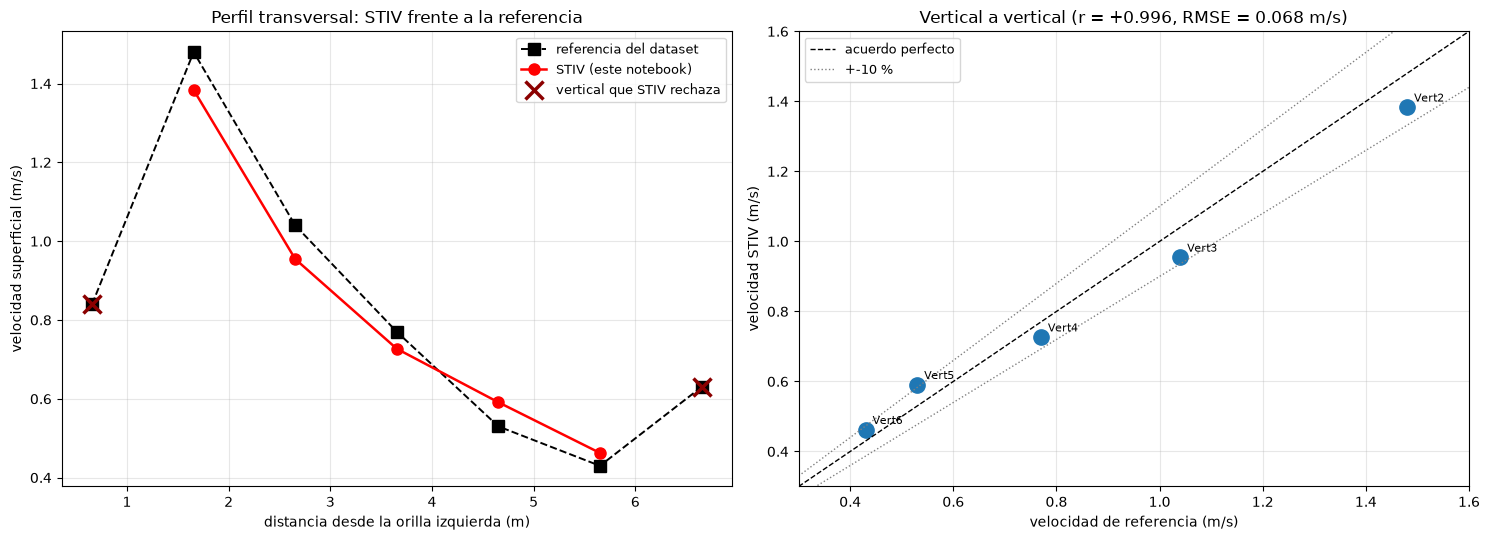

                                             concepto   valor                                     unidad
                 Velocidad superficial mediana (STIV)  0.7270                                        m/s
     Velocidad media de las verticales medidas (STIV)  0.8238                                        m/s
Velocidad media de las mismas verticales (referencia)  0.8500                                        m/s
                                          Sesgo medio -0.0262                                        m/s
                                 Sesgo medio relativo -3.0800                                          %
                                                 RMSE  0.0682                                        m/s
                                        Correlacion r  0.9962                                          -
                     Verticales de validacion medidas  5.0000                                       de 7
                                   Estaciones validas  

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.plot(comparacion.s_m, comparacion.v_ref, "ks--", ms=8, lw=1.4, label="referencia del dataset")
ax.plot(emparejadas.s_m, emparejadas.v_stiv, "r-o", ms=8, lw=1.8, label="STIV (este notebook)")
rech = comparacion[comparacion.v_stiv.isna()]
ax.plot(rech.s_m, rech.v_ref, "x", color="darkred", ms=13, mew=2.5,
        label="vertical que STIV rechaza")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad superficial (m/s)")
ax.set_title("Perfil transversal: STIV frente a la referencia")
ax.grid(alpha=0.3); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(emparejadas.v_ref, emparejadas.v_stiv, "o", ms=11, color="tab:blue")
for r_ in emparejadas.itertuples():
    ax.annotate(r_.vertical, (r_.v_ref, r_.v_stiv), fontsize=8,
                xytext=(5, 4), textcoords="offset points")
lim = [0.3, 1.6]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.plot(lim, [1.1 * x for x in lim], ":", color="gray", lw=1, label="+-10 %")
ax.plot(lim, [0.9 * x for x in lim], ":", color="gray", lw=1)
ax.set_xlabel("velocidad de referencia (m/s)")
ax.set_ylabel("velocidad STIV (m/s)")
ax.set_title(f"Vertical a vertical (r = {r:+.3f}, RMSE = {rmse:.3f} m/s)")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(alpha=0.3); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

resumen = pd.DataFrame([
    dict(concepto="Velocidad superficial mediana (STIV)", valor=round(v_mediana, 4), unidad="m/s"),
    dict(concepto="Velocidad media de las verticales medidas (STIV)",
         valor=round(float(emparejadas.v_stiv.mean()), 4), unidad="m/s"),
    dict(concepto="Velocidad media de las mismas verticales (referencia)",
         valor=round(float(emparejadas.v_ref.mean()), 4), unidad="m/s"),
    dict(concepto="Sesgo medio", valor=round(sesgo, 4), unidad="m/s"),
    dict(concepto="Sesgo medio relativo",
         valor=round(100 * sesgo / float(emparejadas.v_ref.mean()), 2), unidad="%"),
    dict(concepto="RMSE", valor=round(rmse, 4), unidad="m/s"),
    dict(concepto="Correlacion r", valor=round(r, 4), unidad="-"),
    dict(concepto="Verticales de validacion medidas", valor=len(emparejadas), unidad="de 7"),
    dict(concepto="Estaciones validas", valor=int(valida.sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Escala (dada por el dataset)", valor=ESCALA, unidad="m/px"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: el dataset no da batimetria"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
print(resumen.to_string(index=False))
print(f"\nGuardado en: {SALIDA_RESUMEN}")

---
## Limitaciones conocidas

1. **No hay caudal, y no lo habra con este dataset.** El release publica video, escala y siete
   velocidades de referencia. Sin batimetria no hay area. Es el mismo techo que en Boneyard Creek,
   un escalon por encima: alli faltaba tambien la escala.
2. **Las dos estaciones junto a las orillas no se miden.** La 0 (a 0.66 m de la orilla izquierda)
   queda en sombra del talud y sin particulas; la 8 pisa la grava. Es la misma debilidad
   adyacente a la pared que tienen los cuatro casos de STIV del workspace, y aqui ademas la
   referencia da 0.84 y 0.63 m/s en dos de esas posiciones, o sea que hay agua corriendo y lo que
   falla es la visibilidad del trazador, no la fisica.
3. **El video viene comprimido con perdida.** El dataset no publica los fotogramas en crudo. El
   ruido de bloque entra directamente en los gradientes de los que vive el tensor. No es
   cuantificable sin el original.
4. **La direccion del flujo se impone, no se mide.** `ANGULO_FLUJO = -90` es la vertical de la
   imagen. La desviacion real medida por correlacion de fase llega a 4 grados en la parte activa
   del cauce, que cuesta un 0.2 % en el modulo; en la mitad derecha, donde el agua esta casi
   parada, llega a 10 grados, pero ahi las estaciones se rechazan de todos modos.
5. **La escala se toma del `Readme.txt`, no se verifica de forma independiente.** La comprobacion
   de la Parte 2 (verticales separadas 111 px = 0.999 m) es consistente pero no cierra el circulo:
   confirma que 0.009 m/px y una malla de 1 m son compatibles, no que ambas sean correctas.
6. **La banda promedia 0.216 m a traves de la seccion.** Es lo que hace medible el caso, y a
   cambio suaviza el perfil transversal. Con estaciones separadas 1 m el efecto es del orden del
   20 %, y se nota justamente donde el perfil es mas curvo, cerca del pico.
7. **Una sola ventana temporal.** El notebook mide los 25 s de golpe y da un numero por estacion.
   La variabilidad temporal la resuelve `video_velocidad.py`, que repite la medida en ventanas
   deslizantes sobre el video entero.

## Equivalencia con los otros casos del workspace

| | Sile Main Canal (STIV) | Boneyard Creek | Hommerich | **Bradano** |
|---|---|---|---|---|
| Camara | dron cenital | oblicua fija | oblicua fija | dron cenital |
| Ortorrectificacion | ninguna (ya es cenital) | homografia por punto de fuga | `remap` por `solvePnP` | **la trae el dataset** |
| Escala | deducida de 2 lineas de agua | **no existe** (unidades afines) | de los GCP RTK | **dada: 0.009 m/px** |
| Estabilizacion | script propio, 1.1 GB | no hace falta (0.02 px) | no hace falta | **la trae el dataset** |
| Trazador | espuma continua | espuma fina | natural | **particulas dispersas** |
| Linea de busqueda | una | una | una | **banda de 7** |
| QC | coherencia | contraste temporal | contraste + coherencia | **brillo + coherencia** |
| Rellena huecos | si (hay que integrar) | no | si | **no** |
| Resultado | caudal m3/s | velocidad en alturas de camara/s | caudal m3/s | **velocidad m/s** |

## Resumen de las constantes `>>> AJUSTABLE <<<`

| Parte | Constante | Valor | De donde sale |
|---|---|---|---|
| 2 | `ESCALA` | 0.009 m/px | `Readme.txt` del dataset |
| 2 | `FILA_SECCION` | 706 | hoja de validacion (posiciones) |
| 2 | `COLUMNA_AGUA_IZQ/DER` | 383 / 1353 | perfil de brillo, fig2 |
| 2 | `COLUMNA_ESTACION_0`, `PASO_ESTACION_PX`, `N_ESTACIONES` | 456, 111, 9 | malla del aforo, prolongada |
| 2 | `ANGULO_FLUJO` | -90 grados | vertical de la imagen |
| 3 | `V_ESPERADA` | 0.9 m/s | correlacion de fase, a priori |
| 3 | `N_FRAMES` | 600 | el video entero |
| 3 | `LARGO_STI` | 128 muestras | ~4.6 m de rio |
| 3 | `ANCHO_BANDA`, `PASO_BANDA` | 24, 4 px | tabla de coherencia de la Parte 3 |
| 4 | `LADO_BLOQUE`, `COH_MIN_BLOQUE`, `SIGMA_DERIVADA` | 64, 0.50, 1.5 | los mismos que el caso del Sile |
| 4b | `COH_MIN_ESTACION` | 0.70 | el mismo que el caso del Sile |
| 4b | `BRILLO_MAX_AGUA` | 5.0 | hueco medido agua/grava (0.42 vs 12.59) |

## Y despues

`video_velocidad.py`, en esta misma carpeta, repite exactamente este STIV en ventanas deslizantes
sobre los 600 fotogramas y escribe `salidas/velocidad_tiempo_real.mp4`, con las lineas de busqueda,
una flecha por estacion y su valor en m/s. **Duplica las constantes de este notebook**: si se
cambia una aqui, hay que cambiarla alli.